In [2]:
!pip install -q keras-tuner

import os, re, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

# ---------------- Global configuration ----------------
SEED         = 42       # reproducibility
MAX_WORDS    = 10000    # vocabulary size
MAX_LEN      = 200      # sequence length after padding/truncation
MAX_TRIALS   = 6        # random configurations tried per model
TUNE_EPOCHS  = 8        # epochs per tuning trial
FINAL_EPOCHS = 15       # max epochs when retraining the best config
SAMPLE_SIZE  = None     # set e.g. 20000 for a quick test run

keras.utils.set_random_seed(SEED)   # seeds Python, NumPy, TensorFlow
os.makedirs("results", exist_ok=True)
sns.set_theme(style="whitegrid")

print("TensorFlow:", tf.__version__, "| KerasTuner:", keras_tuner.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "None (will be slow)")

TensorFlow: 2.21.0 | KerasTuner: 1.4.8
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Cell 2 - Load Dataset (Hugging Face version)
!pip install -q datasets

from datasets import load_dataset, concatenate_datasets

# Download IMDB from Hugging Face (try the new name first, then the old one)
try:
    ds = load_dataset("stanfordnlp/imdb")
except Exception:
    ds = load_dataset("imdb")

print(ds)   # shows the available splits: train, test, unsupervised

# Pool the labeled train + test splits (50,000 reviews); we re-split ourselves later.
# The "unsupervised" split has no labels, so we ignore it.
full = concatenate_datasets([ds["train"], ds["test"]])

# Convert to a pandas DataFrame with the same column names as before
df = full.to_pandas()[["text", "label"]].rename(columns={"text": "review"})

# Shuffle (the data comes sorted: all negatives first, then positives)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
if SAMPLE_SIZE:
    df = df.head(SAMPLE_SIZE)

print("\nLoaded:", df.shape)
print("Labels (0 = negative, 1 = positive):")
print(df["label"].value_counts())

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Loaded: (50000, 2)
Labels (0 = negative, 1 = positive):
label
0    25000
1    25000
Name: count, dtype: int64


Shape: (50000, 2)

Missing values:
 review    0
label     0
dtype: int64

Duplicate reviews: 418

Class counts:
 label
0    25000
1    25000
Name: count, dtype: int64

Review length (words):
 count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: review, dtype: float64

Sample records:


,review,label
33553,"Every now and then some amateur will come out with a tired piece of action film making. this one is just so wrong I don't think i even need to comment about the plot, acting, script, camera work. ...",0
9427,"This film is about the worst I have seen in a very long time. Terence Stamp's talent is totally wasted and just about the only thing that I enjoyed was hearing a favorite song of mine, ""If I Had a...",0
199,"""When I die, someone will bury me. And if they don't, what's the difference. Who gives a damn, huh?"" Thus the philosophy of life (or lack there of) is summed up once and for all in this less than ...",1


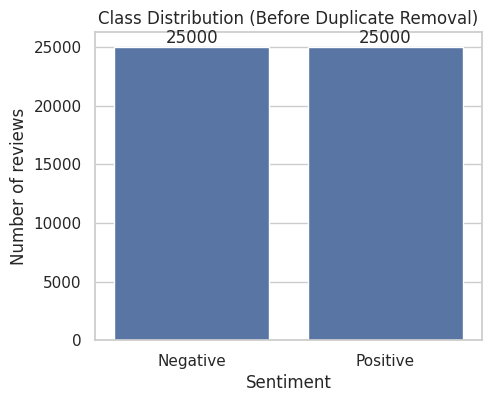

In [4]:
pd.set_option("display.max_colwidth", 200)
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate reviews:", df.duplicated(subset="review").sum())
print("\nClass counts:\n", df["label"].value_counts())
print("\nReview length (words):\n", df["review"].str.split().str.len().describe())
print("\nSample records:")
display(df.sample(3, random_state=SEED))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x=df["label"].map({0: "Negative", 1: "Positive"}),
                   order=["Negative", "Positive"])
for c in ax.containers: ax.bar_label(c)
plt.title("Class Distribution (Before Duplicate Removal)")
plt.xlabel("Sentiment"); plt.ylabel("Number of reviews")
plt.savefig("results/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
df = df.dropna(subset=["review", "label"])
before = len(df)
df = df.drop_duplicates(subset="review").reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate reviews. Remaining: {len(df)}")

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)                   # remove HTML tags
    text = re.sub(r"[^a-z0-9!?' ]+", " ", text)            # keep letters, digits, ! ? '
    text = re.sub(r"(?<![a-z])'|'(?![a-z])", " ", text)    # drop quote marks, keep don't
    text = re.sub(r"([!?])", r" \1 ", text)                # make ! and ? separate tokens
    return re.sub(r"\s+", " ", text).strip()

df["clean_review"] = df["review"].apply(clean_text)
df["label"] = df["label"].astype(int)                      # labels already 0/1

print("\nBEFORE:", df["review"][0][:250])
print("AFTER :", df["clean_review"][0][:250])

Removed 418 duplicate reviews. Remaining: 49582

BEFORE: Forget what I said about Emeril. Rachael Ray is the most irritating personality on the Food Network AND all of television. If you've never seen 30 Minute Meals, then you cannot possibly begin to comprehend how unfathomably annoying she is. I really t
AFTER : forget what i said about emeril rachael ray is the most irritating personality on the food network and all of television if you've never seen 30 minute meals then you cannot possibly begin to comprehend how unfathomably annoying she is i really truly


In [6]:
texts, labels = df["clean_review"].tolist(), df["label"].values

train_texts, temp_texts, y_train, y_temp = train_test_split(
    texts, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_texts, test_texts, y_val, y_test = train_test_split(
    temp_texts, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"Train: {len(train_texts)} | Validation: {len(val_texts)} | Test: {len(test_texts)}")
print("Positive ratio  train/val/test:",
      round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Train: 34707 | Validation: 7437 | Test: 7438
Positive ratio  train/val/test: 0.502 0.502 0.502


In [7]:
vectorizer = layers.TextVectorization(
    max_tokens=MAX_WORDS, standardize=None, split="whitespace",
    output_mode="int", output_sequence_length=MAX_LEN)

# Learn vocabulary from TRAINING text only (prevents leakage)
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(train_texts).batch(256))

vocab = vectorizer.get_vocabulary()
VOCAB_SIZE = len(vocab)
print("Vocabulary size:", VOCAB_SIZE, "| first entries:", vocab[:10])

def encode(text_list):
    return vectorizer(tf.constant(list(text_list))).numpy().astype("int32")

X_train, X_val, X_test = encode(train_texts), encode(val_texts), encode(test_texts)
print("Shapes:", X_train.shape, X_val.shape, X_test.shape)

# Example: words -> numbers -> padding
example = "this movie was not amazing"
ids = encode([example])[0]
print(f"\n'{example}'\n -> {ids[:10]} ...(padded with zeros to length {MAX_LEN})")
print("Decoded:", [vocab[i] for i in ids[:5]])

# Unknown-word rate and truncation rate
non_pad = (X_val != 0).sum()
print(f"\nUnknown-word rate in validation: {(X_val == 1).sum() / non_pad:.2%}")
lens = np.array([len(t.split()) for t in train_texts])
print(f"Training reviews longer than {MAX_LEN} words (truncated): {(lens > MAX_LEN).mean():.2%}")

Vocabulary size: 10000 | first entries: ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it')]
Shapes: (34707, 200) (7437, 200) (7438, 200)

'this movie was not amazing'
 -> [ 11  17  13  21 488   0   0   0   0   0] ...(padded with zeros to length 200)
Decoded: [np.str_('this'), np.str_('movie'), np.str_('was'), np.str_('not'), np.str_('amazing')]

Unknown-word rate in validation: 5.47%
Training reviews longer than 200 words (truncated): 41.51%


In [8]:
MODEL_NAMES = ["Neural Network", "RNN", "LSTM", "GRU"]
results = {}   # everything for each model is stored here

def make_model(model_type, embedding_dim, units, dense_units, dropout, learning_rate):
    inputs = keras.Input(shape=(MAX_LEN,), dtype="int32")
    x = layers.Embedding(VOCAB_SIZE, embedding_dim, mask_zero=True)(inputs)

    if model_type == "Neural Network":
        x = layers.GlobalAveragePooling1D()(x)     # average word vectors (ignores padding)
    elif model_type == "RNN":
        x = layers.SimpleRNN(units)(x)
    elif model_type == "LSTM":
        x = layers.LSTM(units)(x)
    elif model_type == "GRU":
        x = layers.GRU(units)(x)

    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)   # probability of "positive"

    model = keras.Model(inputs, outputs, name=model_type.replace(" ", "_"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss="binary_crossentropy", metrics=["accuracy"])
    return model

class SentimentHyperModel(keras_tuner.HyperModel):
    def __init__(self, model_type):
        super().__init__()
        self.model_type = model_type

    def build(self, hp):
        # ---------- predefined search space ----------
        embedding_dim = hp.Choice("embedding_dim", [32, 64, 128])
        units = None if self.model_type == "Neural Network" else hp.Choice("units", [32, 64, 128])
        dense_units   = hp.Choice("dense_units", [32, 64, 128])
        dropout       = hp.Choice("dropout", [0.0, 0.2, 0.3, 0.5])
        learning_rate = hp.Choice("learning_rate", [1e-3, 5e-4, 1e-4])
        hp.Choice("batch_size", [16, 32, 64])        # registered here, used in fit()
        return make_model(self.model_type, embedding_dim, units, dense_units, dropout, learning_rate)

    def fit(self, hp, model, *args, **kwargs):
        return model.fit(*args, batch_size=hp.Choice("batch_size", [16, 32, 64]), **kwargs)

def run_tuning(model_type):
    print(f"\n{'='*60}\nTUNING: {model_type}\n{'='*60}")
    keras.utils.set_random_seed(SEED)

    tuner = keras_tuner.RandomSearch(
        SentimentHyperModel(model_type),
        objective="val_accuracy", max_trials=MAX_TRIALS, executions_per_trial=1,
        seed=SEED, directory="tuning", project_name=model_type.replace(" ", "_"),
        overwrite=True)

    stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2,
                                         restore_best_weights=True)
    t0 = time.time()
    tuner.search(X_train, y_train, validation_data=(X_val, y_val),   # validation only, NO test data
                 epochs=TUNE_EPOCHS, callbacks=[stop], verbose=2)
    tuning_time = time.time() - t0

    best_hp = tuner.get_best_hyperparameters(1)[0]
    hp_vals = best_hp.values
    tuner_score = tuner.oracle.get_best_trials(1)[0].score

    # Record every trial (experiment tracking)
    rows = []
    for trial in tuner.oracle.trials.values():
        row = dict(trial.hyperparameters.values)
        row["val_accuracy"] = trial.score
        rows.append(row)
    trials_df = pd.DataFrame(rows).sort_values("val_accuracy", ascending=False).reset_index(drop=True)

    # Retrain best configuration from scratch on the training set
    keras.utils.set_random_seed(SEED)
    model = make_model(model_type, hp_vals["embedding_dim"], hp_vals.get("units"),
                       hp_vals["dense_units"], hp_vals["dropout"], hp_vals["learning_rate"])
    stop_final = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                               restore_best_weights=True)
    t0 = time.time()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=FINAL_EPOCHS, batch_size=hp_vals["batch_size"],
                        callbacks=[stop_final], verbose=2)
    train_time = time.time() - t0

    print(f"\nBest hyperparameters: {hp_vals}")
    print(f"Best tuning-trial validation accuracy: {tuner_score:.4f}")
    print(f"Final training time: {train_time:.0f}s | Tuning time: {tuning_time/60:.1f} min")
    display(trials_df)

    return dict(model=model, history=history.history, hp=hp_vals, tuner_score=tuner_score,
                trials_df=trials_df, train_time=train_time, tuning_time=tuning_time)

print("Tuning framework ready.")

Tuning framework ready.


In [14]:
results["Neural Network"] = run_tuning("Neural Network")

Trial 6 Complete [00h 00m 58s]
val_accuracy: 0.8771010041236877

Best val_accuracy So Far: 0.8771010041236877
Total elapsed time: 00h 02m 39s
Epoch 1/15
2170/2170 - 11s - 5ms/step - accuracy: 0.7463 - loss: 0.5870 - val_accuracy: 0.8292 - val_loss: 0.4293
Epoch 2/15
2170/2170 - 7s - 3ms/step - accuracy: 0.8552 - loss: 0.3572 - val_accuracy: 0.8555 - val_loss: 0.3345
Epoch 3/15
2170/2170 - 6s - 3ms/step - accuracy: 0.8819 - loss: 0.2935 - val_accuracy: 0.8669 - val_loss: 0.3091
Epoch 4/15
2170/2170 - 7s - 3ms/step - accuracy: 0.8964 - loss: 0.2610 - val_accuracy: 0.8739 - val_loss: 0.2994
Epoch 5/15
2170/2170 - 6s - 3ms/step - accuracy: 0.9048 - loss: 0.2400 - val_accuracy: 0.8762 - val_loss: 0.2961
Epoch 6/15
2170/2170 - 7s - 3ms/step - accuracy: 0.9125 - loss: 0.2241 - val_accuracy: 0.8770 - val_loss: 0.2967
Epoch 7/15
2170/2170 - 6s - 3ms/step - accuracy: 0.9195 - loss: 0.2102 - val_accuracy: 0.8760 - val_loss: 0.2999
Epoch 8/15
2170/2170 - 7s - 3ms/step - accuracy: 0.9247 - loss: 0.

,embedding_dim,dense_units,dropout,learning_rate,batch_size,val_accuracy
0,32,128,0.3,0.0001,16,0.877101
1,64,32,0.2,0.0010,64,0.875219
2,64,64,0.0,0.0005,16,0.873202
3,32,64,0.0,0.0010,32,0.871857
4,128,64,0.2,0.0005,16,0.871185
5,128,64,0.5,0.0010,64,0.870512


In [9]:
results["RNN"] = run_tuning("RNN")

Trial 6 Complete [00h 00m 55s]
val_accuracy: 0.8563936948776245

Best val_accuracy So Far: 0.8639236092567444
Total elapsed time: 00h 11m 13s
Epoch 1/15
1085/1085 - 25s - 23ms/step - accuracy: 0.7254 - loss: 0.5385 - val_accuracy: 0.8421 - val_loss: 0.3748
Epoch 2/15
1085/1085 - 19s - 17ms/step - accuracy: 0.8742 - loss: 0.3121 - val_accuracy: 0.8580 - val_loss: 0.3674
Epoch 3/15
1085/1085 - 19s - 17ms/step - accuracy: 0.9043 - loss: 0.2568 - val_accuracy: 0.8431 - val_loss: 0.4026
Epoch 4/15
1085/1085 - 19s - 17ms/step - accuracy: 0.9211 - loss: 0.2209 - val_accuracy: 0.8610 - val_loss: 0.3593
Epoch 5/15
1085/1085 - 19s - 17ms/step - accuracy: 0.9301 - loss: 0.2005 - val_accuracy: 0.8630 - val_loss: 0.3753
Epoch 6/15
1085/1085 - 19s - 17ms/step - accuracy: 0.9394 - loss: 0.1792 - val_accuracy: 0.8550 - val_loss: 0.3682
Epoch 7/15
1085/1085 - 19s - 17ms/step - accuracy: 0.9502 - loss: 0.1553 - val_accuracy: 0.8541 - val_loss: 0.3833
Epoch 8/15
1085/1085 - 19s - 17ms/step - accuracy: 0.

,embedding_dim,units,dense_units,dropout,learning_rate,batch_size,val_accuracy
0,64,32,64,0.0,0.0001,32,0.863924
1,64,32,64,0.2,0.0001,32,0.863789
2,32,32,128,0.2,0.0005,64,0.856394
3,32,32,128,0.3,0.0001,16,0.855452
4,32,64,128,0.2,0.0005,32,0.850746
5,128,32,128,0.0,0.0005,16,0.833401


In [10]:
results["LSTM"] = run_tuning("LSTM")

Trial 6 Complete [00h 00m 34s]
val_accuracy: 0.8690332174301147

Best val_accuracy So Far: 0.8690332174301147
Total elapsed time: 00h 09m 10s
Epoch 1/15
543/543 - 10s - 18ms/step - accuracy: 0.7911 - loss: 0.4254 - val_accuracy: 0.8666 - val_loss: 0.3166
Epoch 2/15
543/543 - 8s - 14ms/step - accuracy: 0.8947 - loss: 0.2693 - val_accuracy: 0.8682 - val_loss: 0.3252
Epoch 3/15
543/543 - 9s - 17ms/step - accuracy: 0.9103 - loss: 0.2398 - val_accuracy: 0.8612 - val_loss: 0.3851
Epoch 4/15
543/543 - 8s - 14ms/step - accuracy: 0.9179 - loss: 0.2236 - val_accuracy: 0.8532 - val_loss: 0.4257
Epoch 5/15
543/543 - 8s - 14ms/step - accuracy: 0.9202 - loss: 0.2165 - val_accuracy: 0.8608 - val_loss: 0.3851

Best hyperparameters: {'embedding_dim': 32, 'units': 32, 'dense_units': 128, 'dropout': 0.2, 'learning_rate': 0.0005, 'batch_size': 64}
Best tuning-trial validation accuracy: 0.8690
Final training time: 42s | Tuning time: 9.2 min


,embedding_dim,units,dense_units,dropout,learning_rate,batch_size,val_accuracy
0,32,32,128,0.2,0.0005,64,0.869033
1,64,32,64,0.0,0.0001,32,0.866882
2,64,32,64,0.2,0.0001,32,0.866075
3,32,64,128,0.2,0.0005,32,0.864461
4,32,32,128,0.3,0.0001,16,0.864058
5,128,32,128,0.0,0.0005,16,0.858814


In [11]:
results["GRU"] = run_tuning("GRU")

Trial 6 Complete [00h 00m 33s]
val_accuracy: 0.8619067072868347

Best val_accuracy So Far: 0.8761597275733948
Total elapsed time: 00h 10m 17s
Epoch 1/15
2170/2170 - 30s - 14ms/step - accuracy: 0.8038 - loss: 0.4269 - val_accuracy: 0.8619 - val_loss: 0.3408
Epoch 2/15
2170/2170 - 28s - 13ms/step - accuracy: 0.8932 - loss: 0.2774 - val_accuracy: 0.8692 - val_loss: 0.3476
Epoch 3/15
2170/2170 - 28s - 13ms/step - accuracy: 0.9233 - loss: 0.2079 - val_accuracy: 0.8724 - val_loss: 0.3539
Epoch 4/15
2170/2170 - 28s - 13ms/step - accuracy: 0.9468 - loss: 0.1579 - val_accuracy: 0.8663 - val_loss: 0.3911
Epoch 5/15
2170/2170 - 28s - 13ms/step - accuracy: 0.9602 - loss: 0.1197 - val_accuracy: 0.8610 - val_loss: 0.4563
Epoch 6/15
2170/2170 - 27s - 13ms/step - accuracy: 0.9721 - loss: 0.0877 - val_accuracy: 0.8623 - val_loss: 0.5107

Best hyperparameters: {'embedding_dim': 128, 'units': 32, 'dense_units': 128, 'dropout': 0.0, 'learning_rate': 0.0005, 'batch_size': 16}
Best tuning-trial validation a

,embedding_dim,units,dense_units,dropout,learning_rate,batch_size,val_accuracy
0,128,32,128,0.0,0.0005,16,0.876160
1,64,32,64,0.2,0.0001,32,0.869974
2,64,32,64,0.0,0.0001,32,0.868092
3,32,64,128,0.2,0.0005,32,0.867958
4,32,32,128,0.3,0.0001,16,0.864193
5,32,32,128,0.2,0.0005,64,0.861907


In [15]:
def evaluate_model(model, X, y):
    probs = model.predict(X, batch_size=256, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    return dict(accuracy=accuracy_score(y, preds),
                precision=precision_score(y, preds),
                recall=recall_score(y, preds),
                f1=f1_score(y, preds),
                cm=confusion_matrix(y, preds))

for name in MODEL_NAMES:
    r = results[name]
    r["val_metrics"]  = evaluate_model(r["model"], X_val,  y_val)
    r["test_metrics"] = evaluate_model(r["model"], X_test, y_test)   # final, untouched test set
    r["params"] = r["model"].count_params()
    r["epochs_run"] = len(r["history"]["loss"])
    print(f"{name:15s} | Val F1: {r['val_metrics']['f1']:.4f} | "
          f"Test Acc: {r['test_metrics']['accuracy']:.4f} | Test F1: {r['test_metrics']['f1']:.4f}")

Neural Network  | Val F1: 0.8778 | Test Acc: 0.8779 | Test F1: 0.8782
RNN             | Val F1: 0.8620 | Test Acc: 0.8634 | Test F1: 0.8613
LSTM            | Val F1: 0.8699 | Test Acc: 0.8717 | Test F1: 0.8726
GRU             | Val F1: 0.8753 | Test Acc: 0.8723 | Test F1: 0.8756


In [16]:
rows = []
for name in MODEL_NAMES:
    r = results[name]; t = r["test_metrics"]; v = r["val_metrics"]
    rows.append({
        "Model": name,
        "Accuracy (%)": t["accuracy"]*100, "Precision (%)": t["precision"]*100,
        "Recall (%)": t["recall"]*100, "F1 Score (%)": t["f1"]*100,
        "Val Accuracy (%)": v["accuracy"]*100, "Val F1 (%)": v["f1"]*100,
        "Parameters": r["params"], "Epochs Run": r["epochs_run"],
        "Training Time (s)": round(r["train_time"], 1),
        "Tuning Time (min)": round(r["tuning_time"]/60, 1)})

# Sorted by VALIDATION F1 (selection criterion); test columns are the final reported scores
comparison_df = (pd.DataFrame(rows)
                 .sort_values(["Val F1 (%)", "Val Accuracy (%)"], ascending=False)
                 .reset_index(drop=True))
comparison_df.iloc[:, 1:7] = comparison_df.iloc[:, 1:7].round(2)
best_name = comparison_df.loc[0, "Model"]

print("FINAL COMPARISON (Accuracy/Precision/Recall/F1 = TEST set; sorted by validation F1)")
display(comparison_df)

# Best hyperparameters table
hp_rows = []
for name in MODEL_NAMES:
    r = results[name]; hp = r["hp"]
    hp_rows.append({
        "Model": name, "Embedding Dim": hp["embedding_dim"], "Units": hp.get("units", "N/A"),
        "Dense Units": hp["dense_units"], "Dropout": hp["dropout"],
        "Learning Rate": hp["learning_rate"], "Batch Size": hp["batch_size"],
        "Validation Score": round(r["tuner_score"], 4)})
best_hp_df = pd.DataFrame(hp_rows)
print("\nBEST HYPERPARAMETERS PER MODEL")
display(best_hp_df)

# Experiment-tracking log of every trial
all_trials_df = pd.concat(
    [results[n]["trials_df"].assign(Model=n) for n in MODEL_NAMES], ignore_index=True)
all_trials_df.insert(0, "Experiment ID", [f"EXP-{i+1:02d}" for i in range(len(all_trials_df))])
all_trials_df = all_trials_df[["Experiment ID", "Model"] +
                              [c for c in all_trials_df.columns if c not in ("Experiment ID", "Model")]]

comparison_df.to_csv("results/model_comparison.csv", index=False)
best_hp_df.to_csv("results/best_hyperparameters.csv", index=False)
all_trials_df.to_csv("results/all_experiments.csv", index=False)
print("\nSaved CSVs to the results/ folder. Total experiments logged:", len(all_trials_df))

FINAL COMPARISON (Accuracy/Precision/Recall/F1 = TEST set; sorted by validation F1)


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),Val Accuracy (%),Val F1 (%),Parameters,Epochs Run,Training Time (s),Tuning Time (min)
0,Neural Network,87.79,87.94,87.70,87.82,87.70,87.78,324353,9,62.5,2.7
1,GRU,87.23,85.63,89.58,87.56,87.24,87.53,1299905,6,168.1,10.3
2,LSTM,87.17,87.00,87.52,87.26,86.82,86.99,332673,5,42.4,9.2
3,RNN,86.34,87.83,84.49,86.13,86.30,86.20,645281,8,156.3,11.2



BEST HYPERPARAMETERS PER MODEL


,Model,Embedding Dim,Units,Dense Units,Dropout,Learning Rate,Batch Size,Validation Score
0,Neural Network,32,N/A,128,0.3,0.0001,16,0.8771
1,RNN,64,32,64,0.0,0.0001,32,0.8639
2,LSTM,32,32,128,0.2,0.0005,64,0.8690
3,GRU,128,32,128,0.0,0.0005,16,0.8762



Saved CSVs to the results/ folder. Total experiments logged: 24


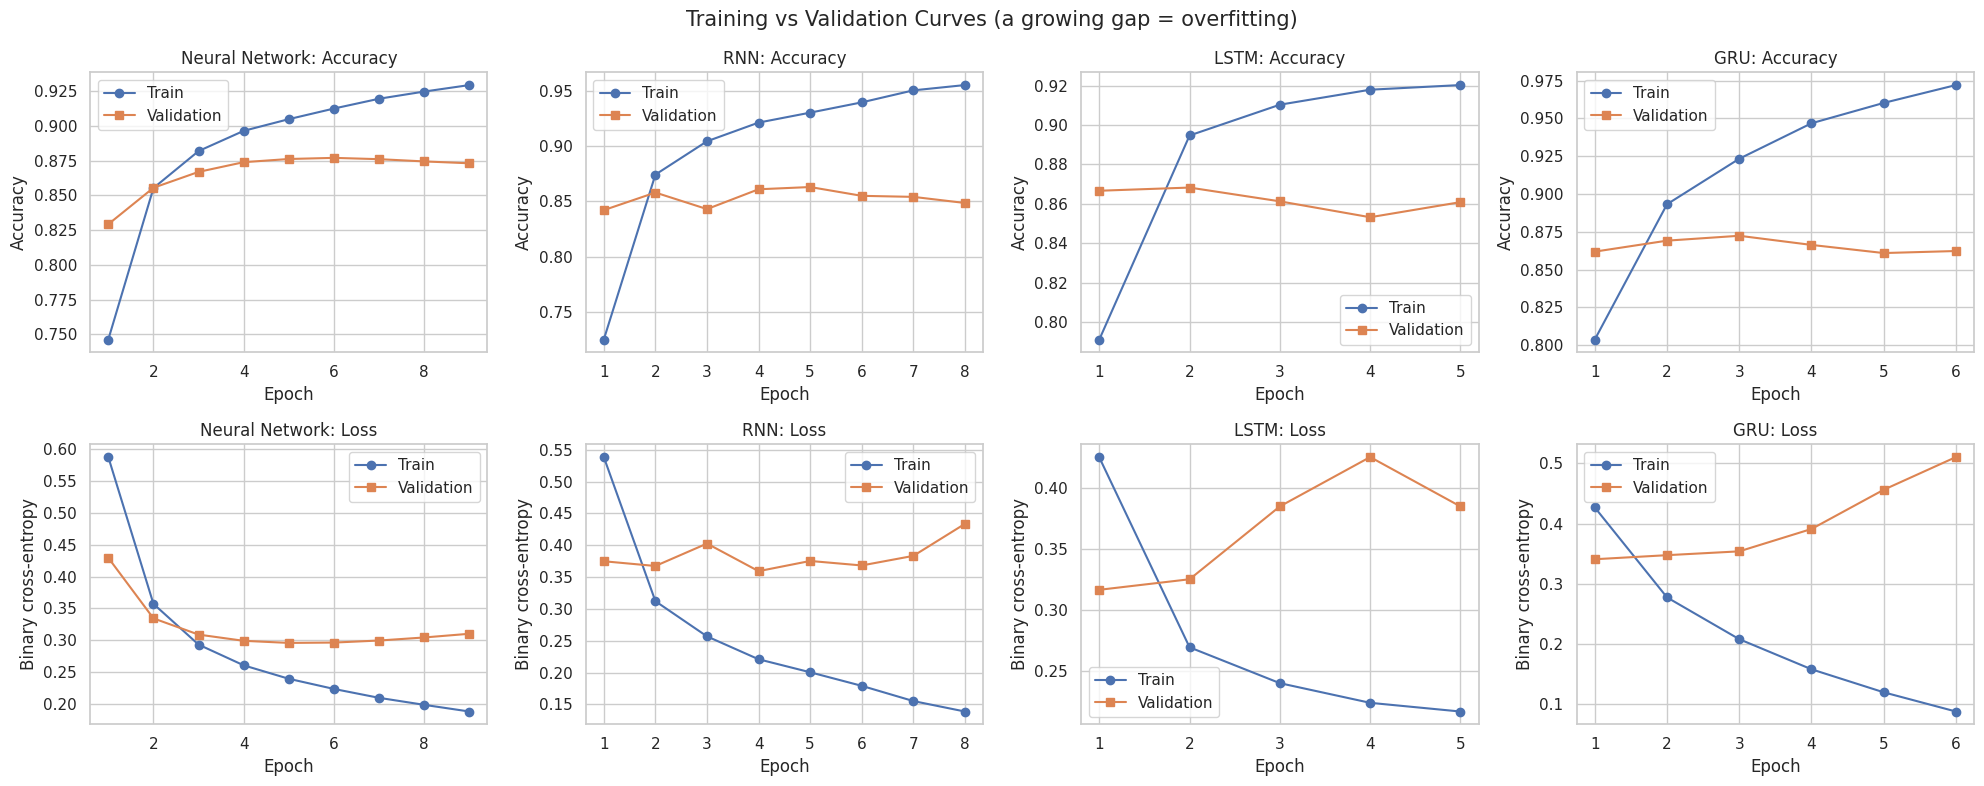

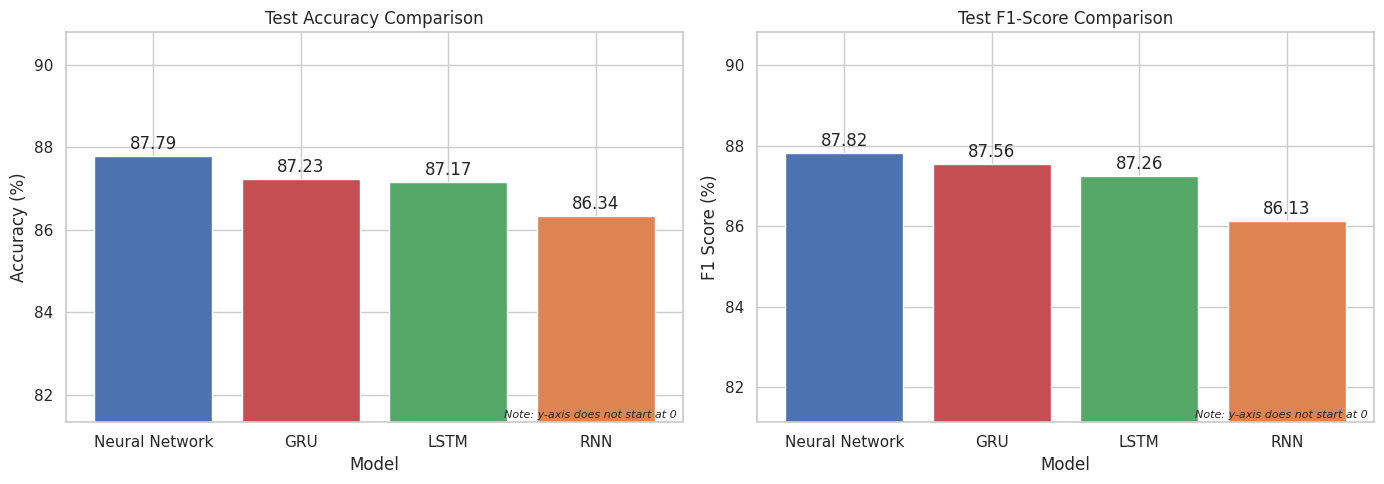

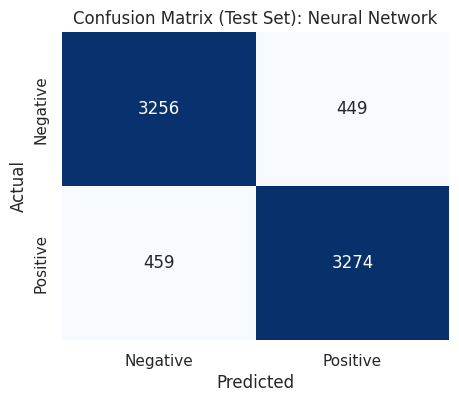

/tmp/ipykernel_1477/3015892022.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_trials_df, x="Model", y="val_accuracy", order=MODEL_NAMES,


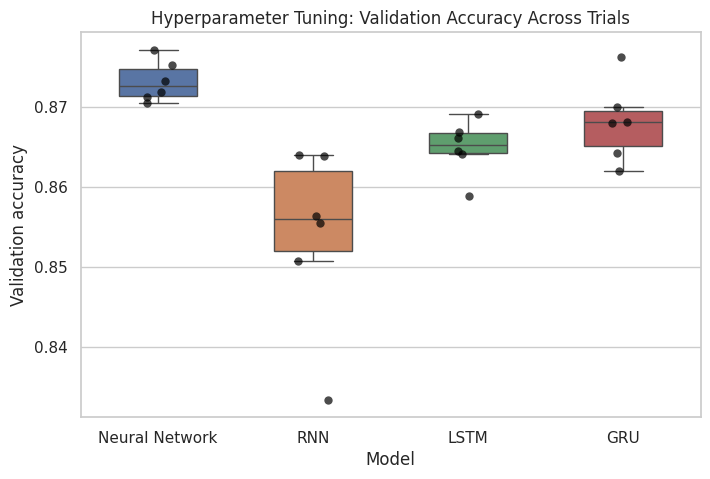

In [17]:
colors = dict(zip(MODEL_NAMES, sns.color_palette("deep", 4)))

# --- Training vs validation accuracy and loss (all four models) ---
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for col, name in enumerate(MODEL_NAMES):
    h = results[name]["history"]; ep = range(1, len(h["loss"]) + 1)
    axes[0, col].plot(ep, h["accuracy"], "o-", label="Train")
    axes[0, col].plot(ep, h["val_accuracy"], "s-", label="Validation")
    axes[0, col].set_title(f"{name}: Accuracy"); axes[0, col].set_xlabel("Epoch")
    axes[0, col].set_ylabel("Accuracy"); axes[0, col].legend()
    axes[1, col].plot(ep, h["loss"], "o-", label="Train")
    axes[1, col].plot(ep, h["val_loss"], "s-", label="Validation")
    axes[1, col].set_title(f"{name}: Loss"); axes[1, col].set_xlabel("Epoch")
    axes[1, col].set_ylabel("Binary cross-entropy"); axes[1, col].legend()
plt.suptitle("Training vs Validation Curves (a growing gap = overfitting)", fontsize=15)
plt.tight_layout()
plt.savefig("results/training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

# --- Accuracy and F1 comparison (test set) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ["Accuracy (%)", "F1 Score (%)"],
                             ["Test Accuracy Comparison", "Test F1-Score Comparison"]):
    bars = ax.bar(comparison_df["Model"], comparison_df[metric],
                  color=[colors[m] for m in comparison_df["Model"]])
    ax.bar_label(bars, fmt="%.2f", padding=2)
    lo = comparison_df[metric].min()
    ax.set_ylim(max(0, lo - 5), min(100, comparison_df[metric].max() + 3))
    ax.set_title(title); ax.set_ylabel(metric); ax.set_xlabel("Model")
    ax.text(0.99, 0.01, "Note: y-axis does not start at 0", transform=ax.transAxes,
            ha="right", fontsize=8, style="italic")
plt.tight_layout()
plt.savefig("results/accuracy_f1_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

# --- Confusion matrix of the best model ---
cm = results[best_name]["test_metrics"]["cm"]
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.title(f"Confusion Matrix (Test Set): {best_name}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig("results/confusion_matrix_best.png", dpi=150, bbox_inches="tight"); plt.show()

# --- Hyperparameter tuning results: validation accuracy of every trial ---
plt.figure(figsize=(8, 5))
sns.boxplot(data=all_trials_df, x="Model", y="val_accuracy", order=MODEL_NAMES,
            palette=colors, width=0.5, fliersize=0)
sns.stripplot(data=all_trials_df, x="Model", y="val_accuracy", order=MODEL_NAMES,
              color="black", size=6, alpha=0.7)
plt.title("Hyperparameter Tuning: Validation Accuracy Across Trials")
plt.ylabel("Validation accuracy"); plt.xlabel("Model")
plt.savefig("results/tuning_trials.png", dpi=150, bbox_inches="tight"); plt.show()

In [18]:
best = results[best_name]; t = best["test_metrics"]; hp = best["hp"]

print("BEST MODEL")
print("-----------")
print(f"Model:     {best_name}")
print(f"Accuracy:  {t['accuracy']*100:.2f}%")
print(f"Precision: {t['precision']*100:.2f}%")
print(f"Recall:    {t['recall']*100:.2f}%")
print(f"F1 Score:  {t['f1']*100:.2f}%")
print("\nBest Hyperparameters:")
print(f"- Embedding Dimension: {hp['embedding_dim']}")
print(f"- Units:               {hp.get('units', 'N/A (no recurrent layer)')}")
print(f"- Dense Units:         {hp['dense_units']}")
print(f"- Dropout:             {hp['dropout']}")
print(f"- Learning Rate:       {hp['learning_rate']}")
print(f"- Batch Size:          {hp['batch_size']}")
print(f"\nSelected using validation F1 = {best['val_metrics']['f1']*100:.2f}% "
      f"(validation accuracy = {best['val_metrics']['accuracy']*100:.2f}%)")

# Sanity check: does the test ranking agree with the validation-based choice?
test_winner = comparison_df.sort_values("F1 Score (%)", ascending=False).iloc[0]["Model"]
print("\nTest-set F1 winner:", test_winner,
      "(agrees with selection)" if test_winner == best_name else
      "(differs - differences this small are within normal run-to-run noise; selection stays validation-based)")

BEST MODEL
-----------
Model:     Neural Network
Accuracy:  87.79%
Precision: 87.94%
Recall:    87.70%
F1 Score:  87.82%

Best Hyperparameters:
- Embedding Dimension: 32
- Units:               N/A (no recurrent layer)
- Dense Units:         128
- Dropout:             0.3
- Learning Rate:       0.0001
- Batch Size:          16

Selected using validation F1 = 87.78% (validation accuracy = 87.70%)

Test-set F1 winner: Neural Network (agrees with selection)


In [19]:
best_model = results[best_name]["model"]

def predict_sentiment(text, threshold=0.5):
    cleaned = clean_text(text)
    seq = vectorizer(tf.constant([cleaned])).numpy().astype("int32")   # same tokenizer + padding
    prob = float(best_model.predict(seq, verbose=0)[0][0])             # P(positive) from sigmoid
    sentiment = "Positive" if prob >= threshold else "Negative"
    print(f"Text: {text}")
    print(f"Sentiment: {sentiment}")
    print(f"Score/Probability of Positive: {prob:.4f}\n")
    return sentiment, prob

predict_sentiment("This movie was absolutely fantastic!")
predict_sentiment("The movie was boring and disappointing.")
predict_sentiment("This movie was not good at all.")       # tests negation handling
predict_sentiment("I didn't hate it, actually it was quite enjoyable.")

Text: This movie was absolutely fantastic!
Sentiment: Positive
Score/Probability of Positive: 0.9998

Text: The movie was boring and disappointing.
Sentiment: Negative
Score/Probability of Positive: 0.0000

Text: This movie was not good at all.
Sentiment: Negative
Score/Probability of Positive: 0.3141

Text: I didn't hate it, actually it was quite enjoyable.
Sentiment: Positive
Score/Probability of Positive: 0.9969



('Positive', 0.9968757629394531)